In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import sys
sys.path.append("../../../SRC/")

### Define Parameters and preprocess the data

In [2]:
from DDG_ANALYSIS.B_PREPROCESS import preprocess

# --- Dictionary mapping file names to their json file paths ---
files = {
    "RFR 2D": "../../../A_MODELS/2D/RANDOM/B_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "RFR 3D": "../../../A_MODELS/3D/RANDOM/B_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "Pycomsia": "../../../A_MODELS/PYC/RANDOM/C_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "Pycomsia (MIF)": "../../../A_MODELS/MIF/RANDOM/C_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "Meta-learner": "../../../A_MODELS/Z_META/DDG/RANDOM/ddG_ridge_LOO_pred&error.json",
    "FEP (OFF)": "../../../A_MODELS/FEP/DDG/OFF/OFF_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json",
    "FEP (OPLS3e)": "../../../A_MODELS/FEP/DDG/OPLS/OPLS_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json"
}

DISPLAY_ORDER = list(files.keys())
ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","thrombin","p2")
METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff"]

results_all, bad_splits = preprocess(files, TARGETS_TO_SKIP)

/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/SRC/DDG_ANALYSIS/A_W_TAU.py:63: RuntimeWarning: invalid value encountered in scalar divide
  tau = (nconcord - ndiscord) / np.sqrt((nconcord + ndiscord + ntx)*(nconcord + ndiscord + nty))


Window tau NaN: method=RFR 3D, target=cdk2, split=70  (NaN is generally due to constant (or in the case of window tau, verry simmilar) values in one of the two input arrays)


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/SRC/DDG_ANALYSIS/A_W_TAU.py:63: RuntimeWarning: invalid value encountered in scalar divide
  tau = (nconcord - ndiscord) / np.sqrt((nconcord + ndiscord + ntx)*(nconcord + ndiscord + nty))


Window tau NaN: method=RFR 3D, target=tyk2, split=95  (NaN is generally due to constant (or in the case of window tau, verry simmilar) values in one of the two input arrays)


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/SRC/DDG_ANALYSIS/A_W_TAU.py:63: RuntimeWarning: invalid value encountered in scalar divide
  tau = (nconcord - ndiscord) / np.sqrt((nconcord + ndiscord + ntx)*(nconcord + ndiscord + nty))


Window tau NaN: method=Pycomsia (MIF), target=jnk1, split=14  (NaN is generally due to constant (or in the case of window tau, verry simmilar) values in one of the two input arrays)


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/SRC/DDG_ANALYSIS/A_W_TAU.py:63: RuntimeWarning: invalid value encountered in scalar divide
  tau = (nconcord - ndiscord) / np.sqrt((nconcord + ndiscord + ntx)*(nconcord + ndiscord + nty))


Window tau NaN: method=Pycomsia (MIF), target=jnk1, split=29  (NaN is generally due to constant (or in the case of window tau, verry simmilar) values in one of the two input arrays)



Removed split summary:
  cdk2: 1 splits removed → [70]
  tyk2: 1 splits removed → [95]
  jnk1: 2 splits removed → [14, 29]


In [3]:
# Check which splits have constant labels or predictions
print(bad_splits)

{'cdk2': {70}, 'tyk2': {95}, 'jnk1': {29, 14}}


### Friedman ANOVA

In [4]:
from DDG_ANALYSIS.C_FRIEDMAN_ANOVA import run_friedman

friedman_results = run_friedman(results_all, METRICS, TARGETS_TO_SKIP=TARGETS_TO_SKIP)
print(friedman_results)

{'rmse': {'bace': {'statistic': 269.66571428571433, 'p_value': 2.5576279969856475e-55}, 'cdk2': {'statistic': 239.24242424242402, 'p_value': 8.14732210912476e-49}, 'cdk8': {'statistic': 307.7571428571432, 'p_value': 1.7797390220631093e-63}, 'cmet': {'statistic': 239.84142857142888, 'p_value': 6.068713465961452e-49}, 'eg5': {'statistic': 234.50142857142873, 'p_value': 8.380508935088991e-48}, 'hif2a': {'statistic': 290.0614285714287, 'p_value': 1.101133226555814e-59}, 'hunt': {'statistic': 260.03999999999996, 'p_value': 2.9288825467115637e-53}, 'jnk1': {'statistic': 218.40524781341128, 'p_value': 2.276631084576875e-44}, 'mcl1': {'statistic': 468.41571428571433, 'p_value': 5.3296848505826234e-98}, 'p38': {'statistic': 148.1185714285716, 'p_value': 1.933378205223674e-29}, 'pde10': {'statistic': 438.84857142857163, 'p_value': 1.2323706474203266e-91}, 'pde2': {'statistic': 340.2128571428575, 'p_value': 1.9464095470407838e-70}, 'pfkfb3': {'statistic': 225.4028571428571, 'p_value': 7.327012083

### Wilcoxon test

In [5]:
from DDG_ANALYSIS.D_WILCOXON import compute_wilcox_posthoc
wilcox_posthoc_results = compute_wilcox_posthoc(results_all, metrics=METRICS, targets_to_skip=TARGETS_TO_SKIP)


### Significance plot

rmse significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


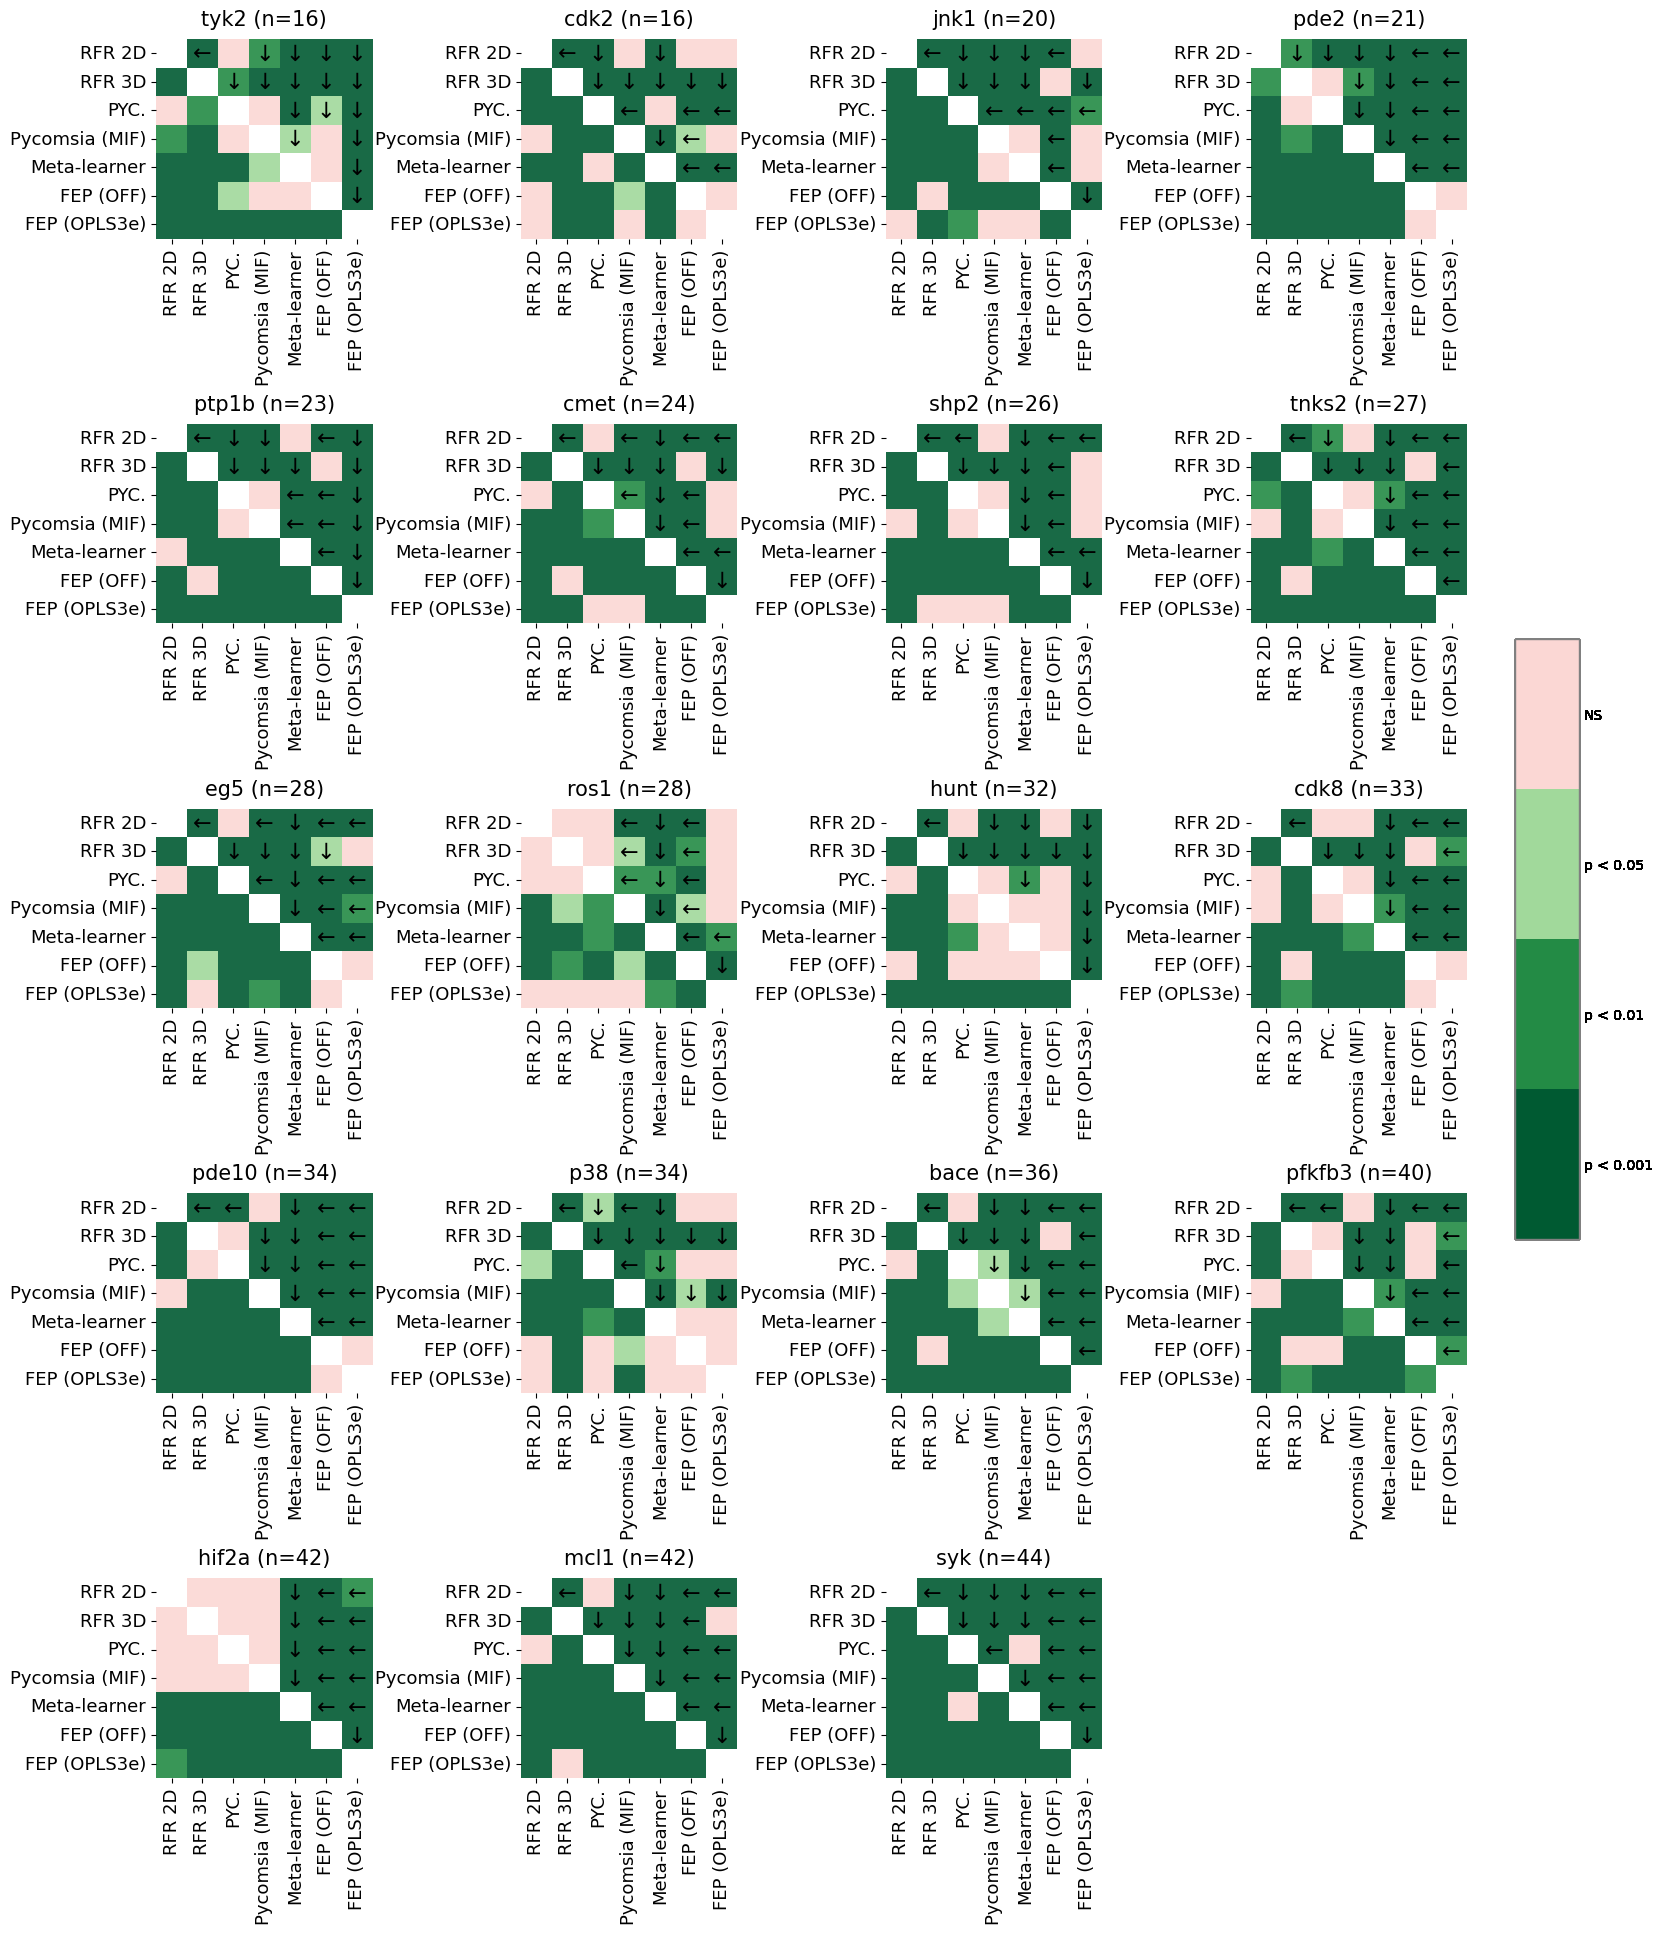

kendalls_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


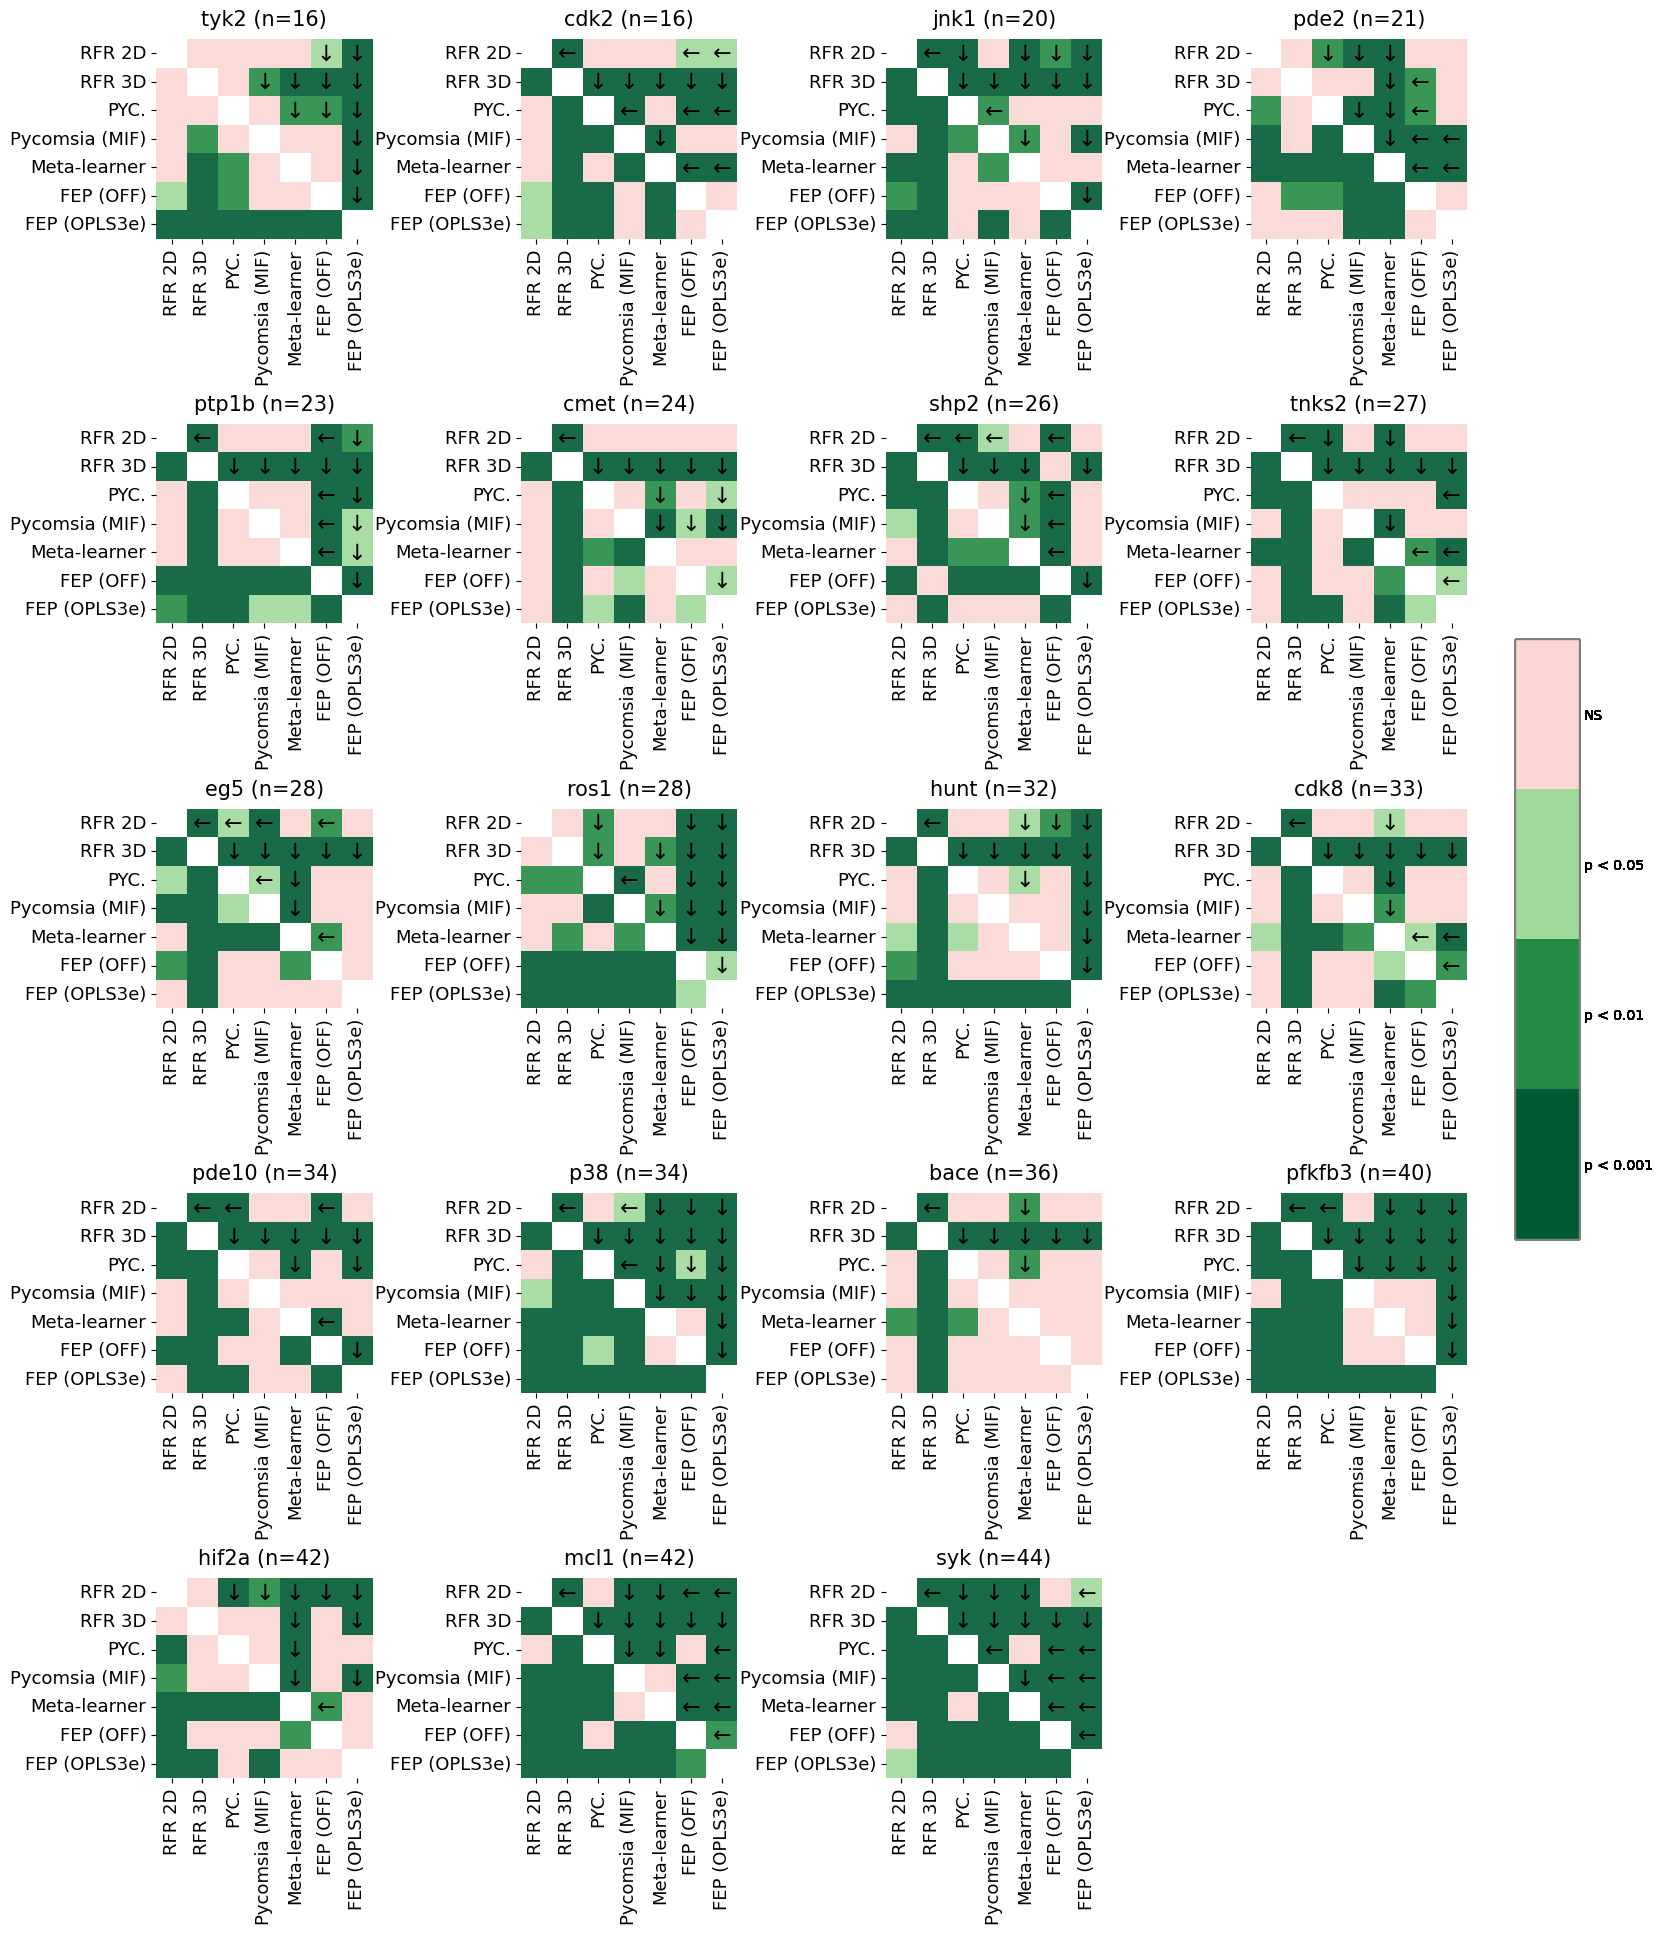

window_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


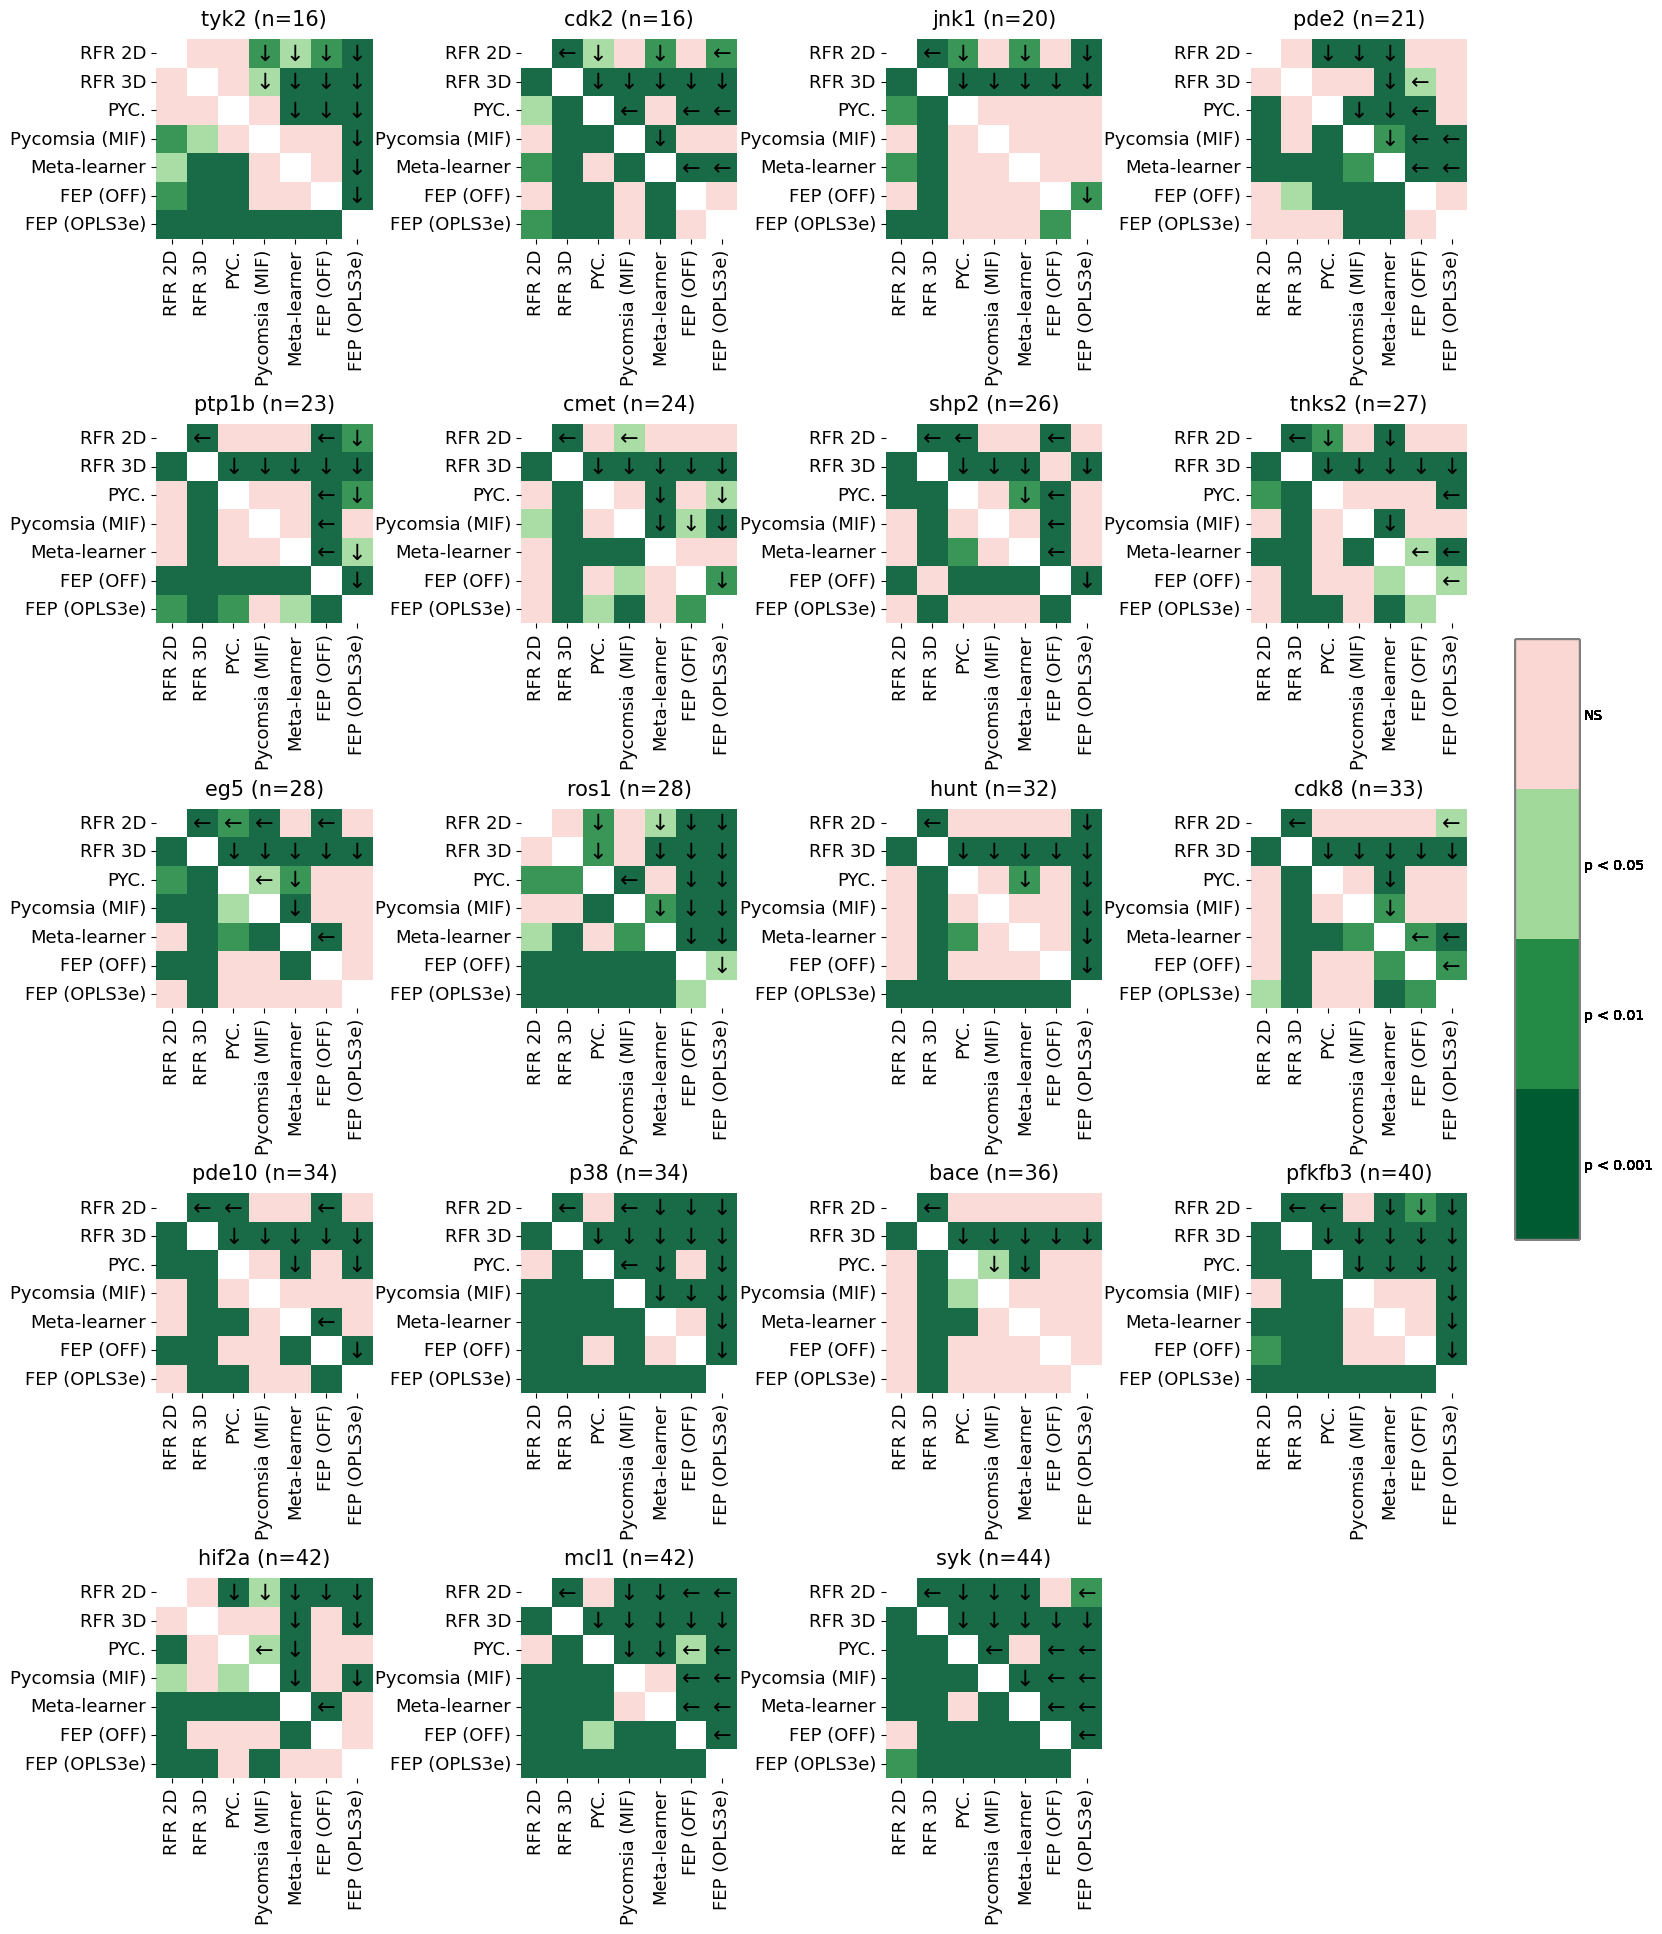

slope_diff significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


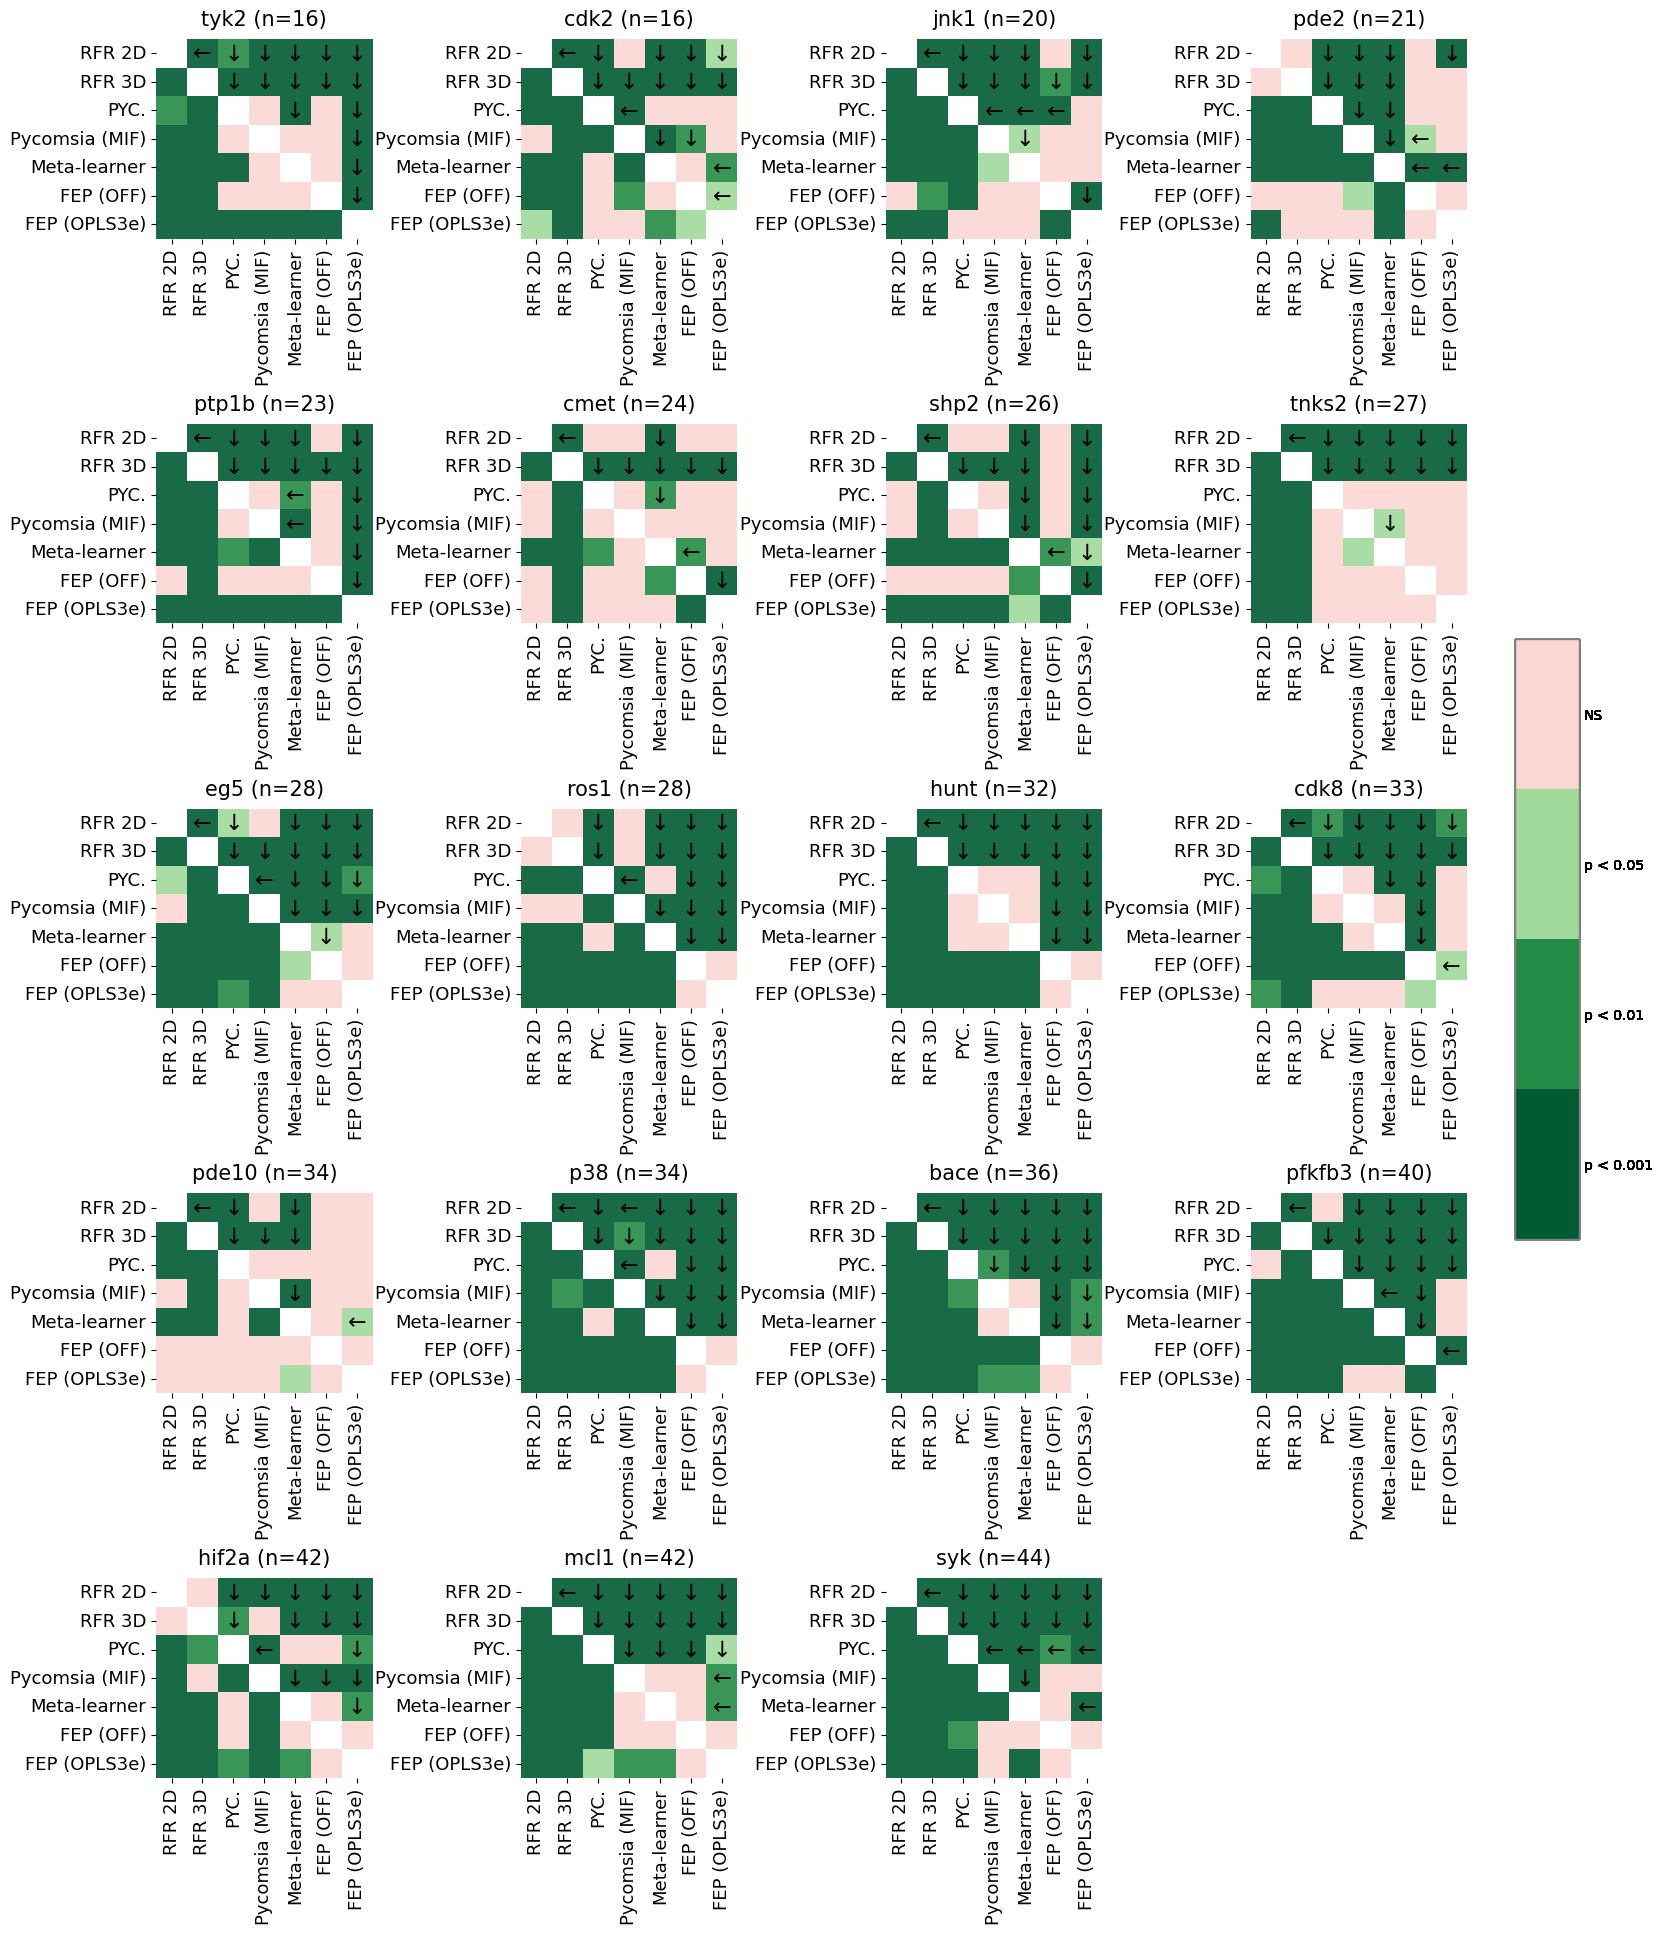

In [6]:
from DDG_ANALYSIS.D_WILCOXON import sign_plot
sign_plot(
    results_all,
    wilcox_posthoc_results,
    DISPLAY_ORDER,
    target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json",
    metrics=METRICS,
    targets_to_skip=TARGETS_TO_SKIP,
    n_cols=4,
    arrow_threshold=0.05, # This is the p value for an arrow to show, should be in accordance with the legend (green -> has an arrow)
    alpha=0.9, # this alpha is how seethrough plot is, not to be mixed up with ALPHA (p value)
)

### Effect size & Significance (Based on wilcoxon)

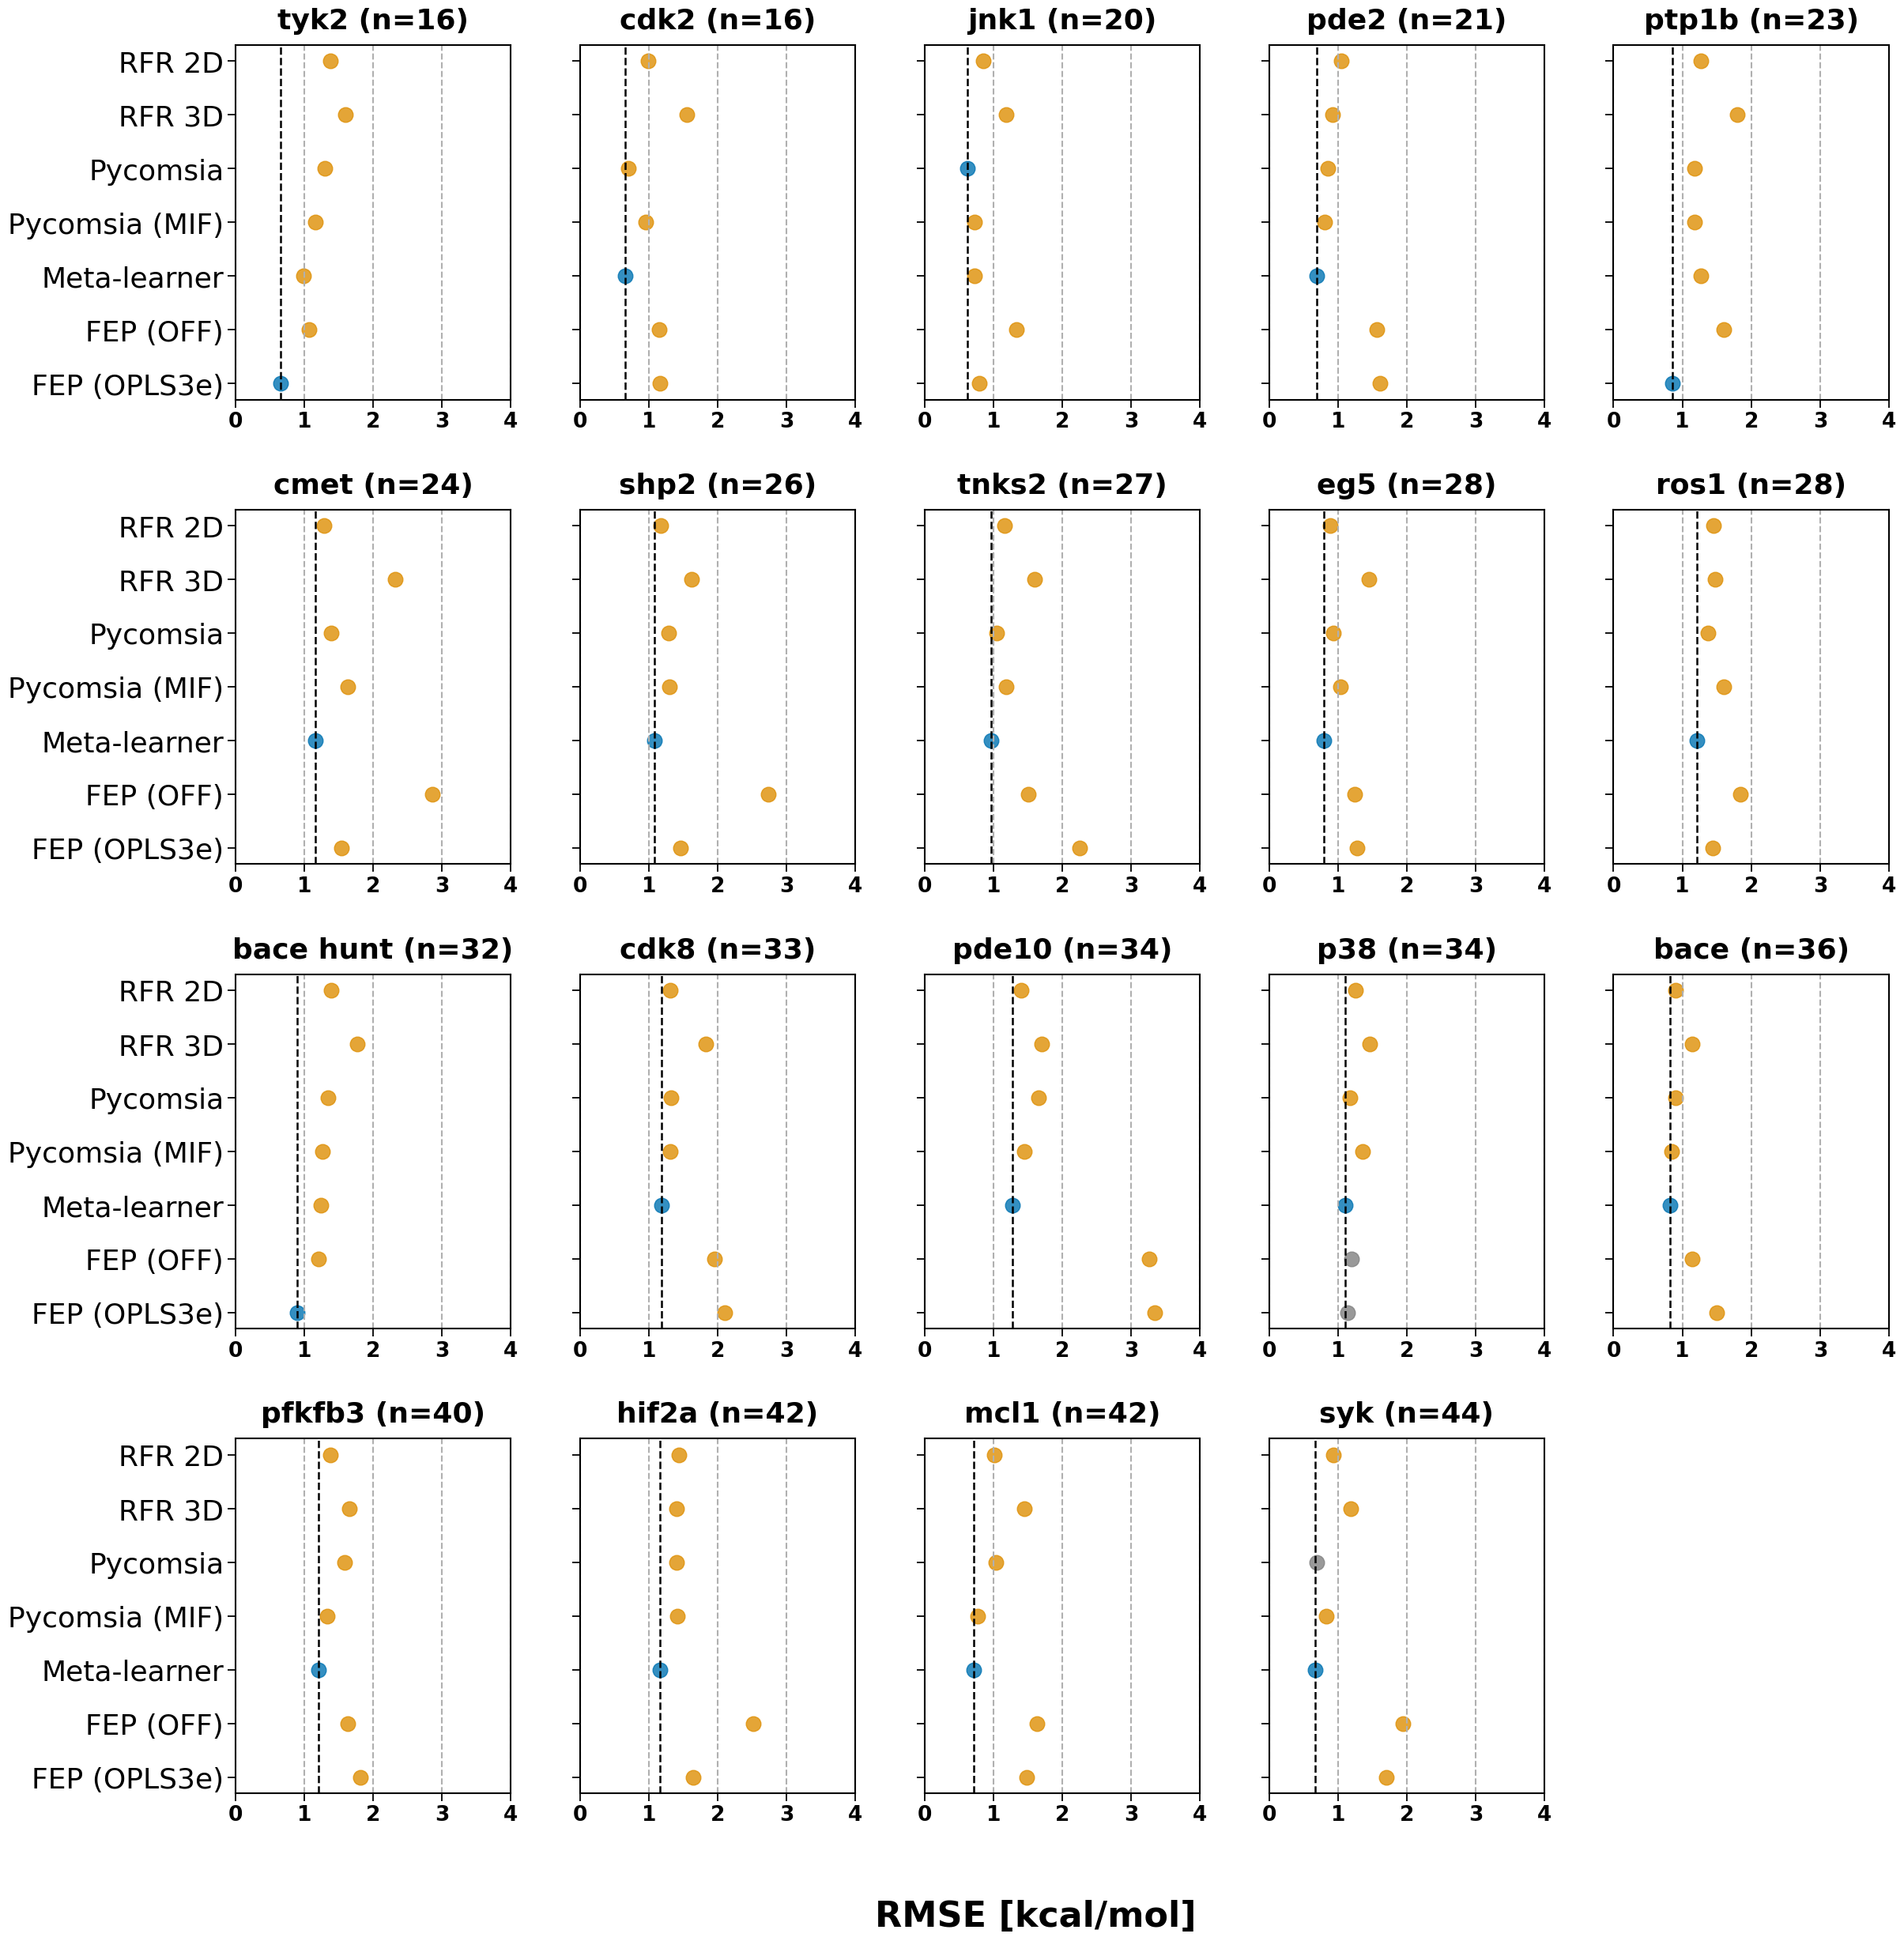

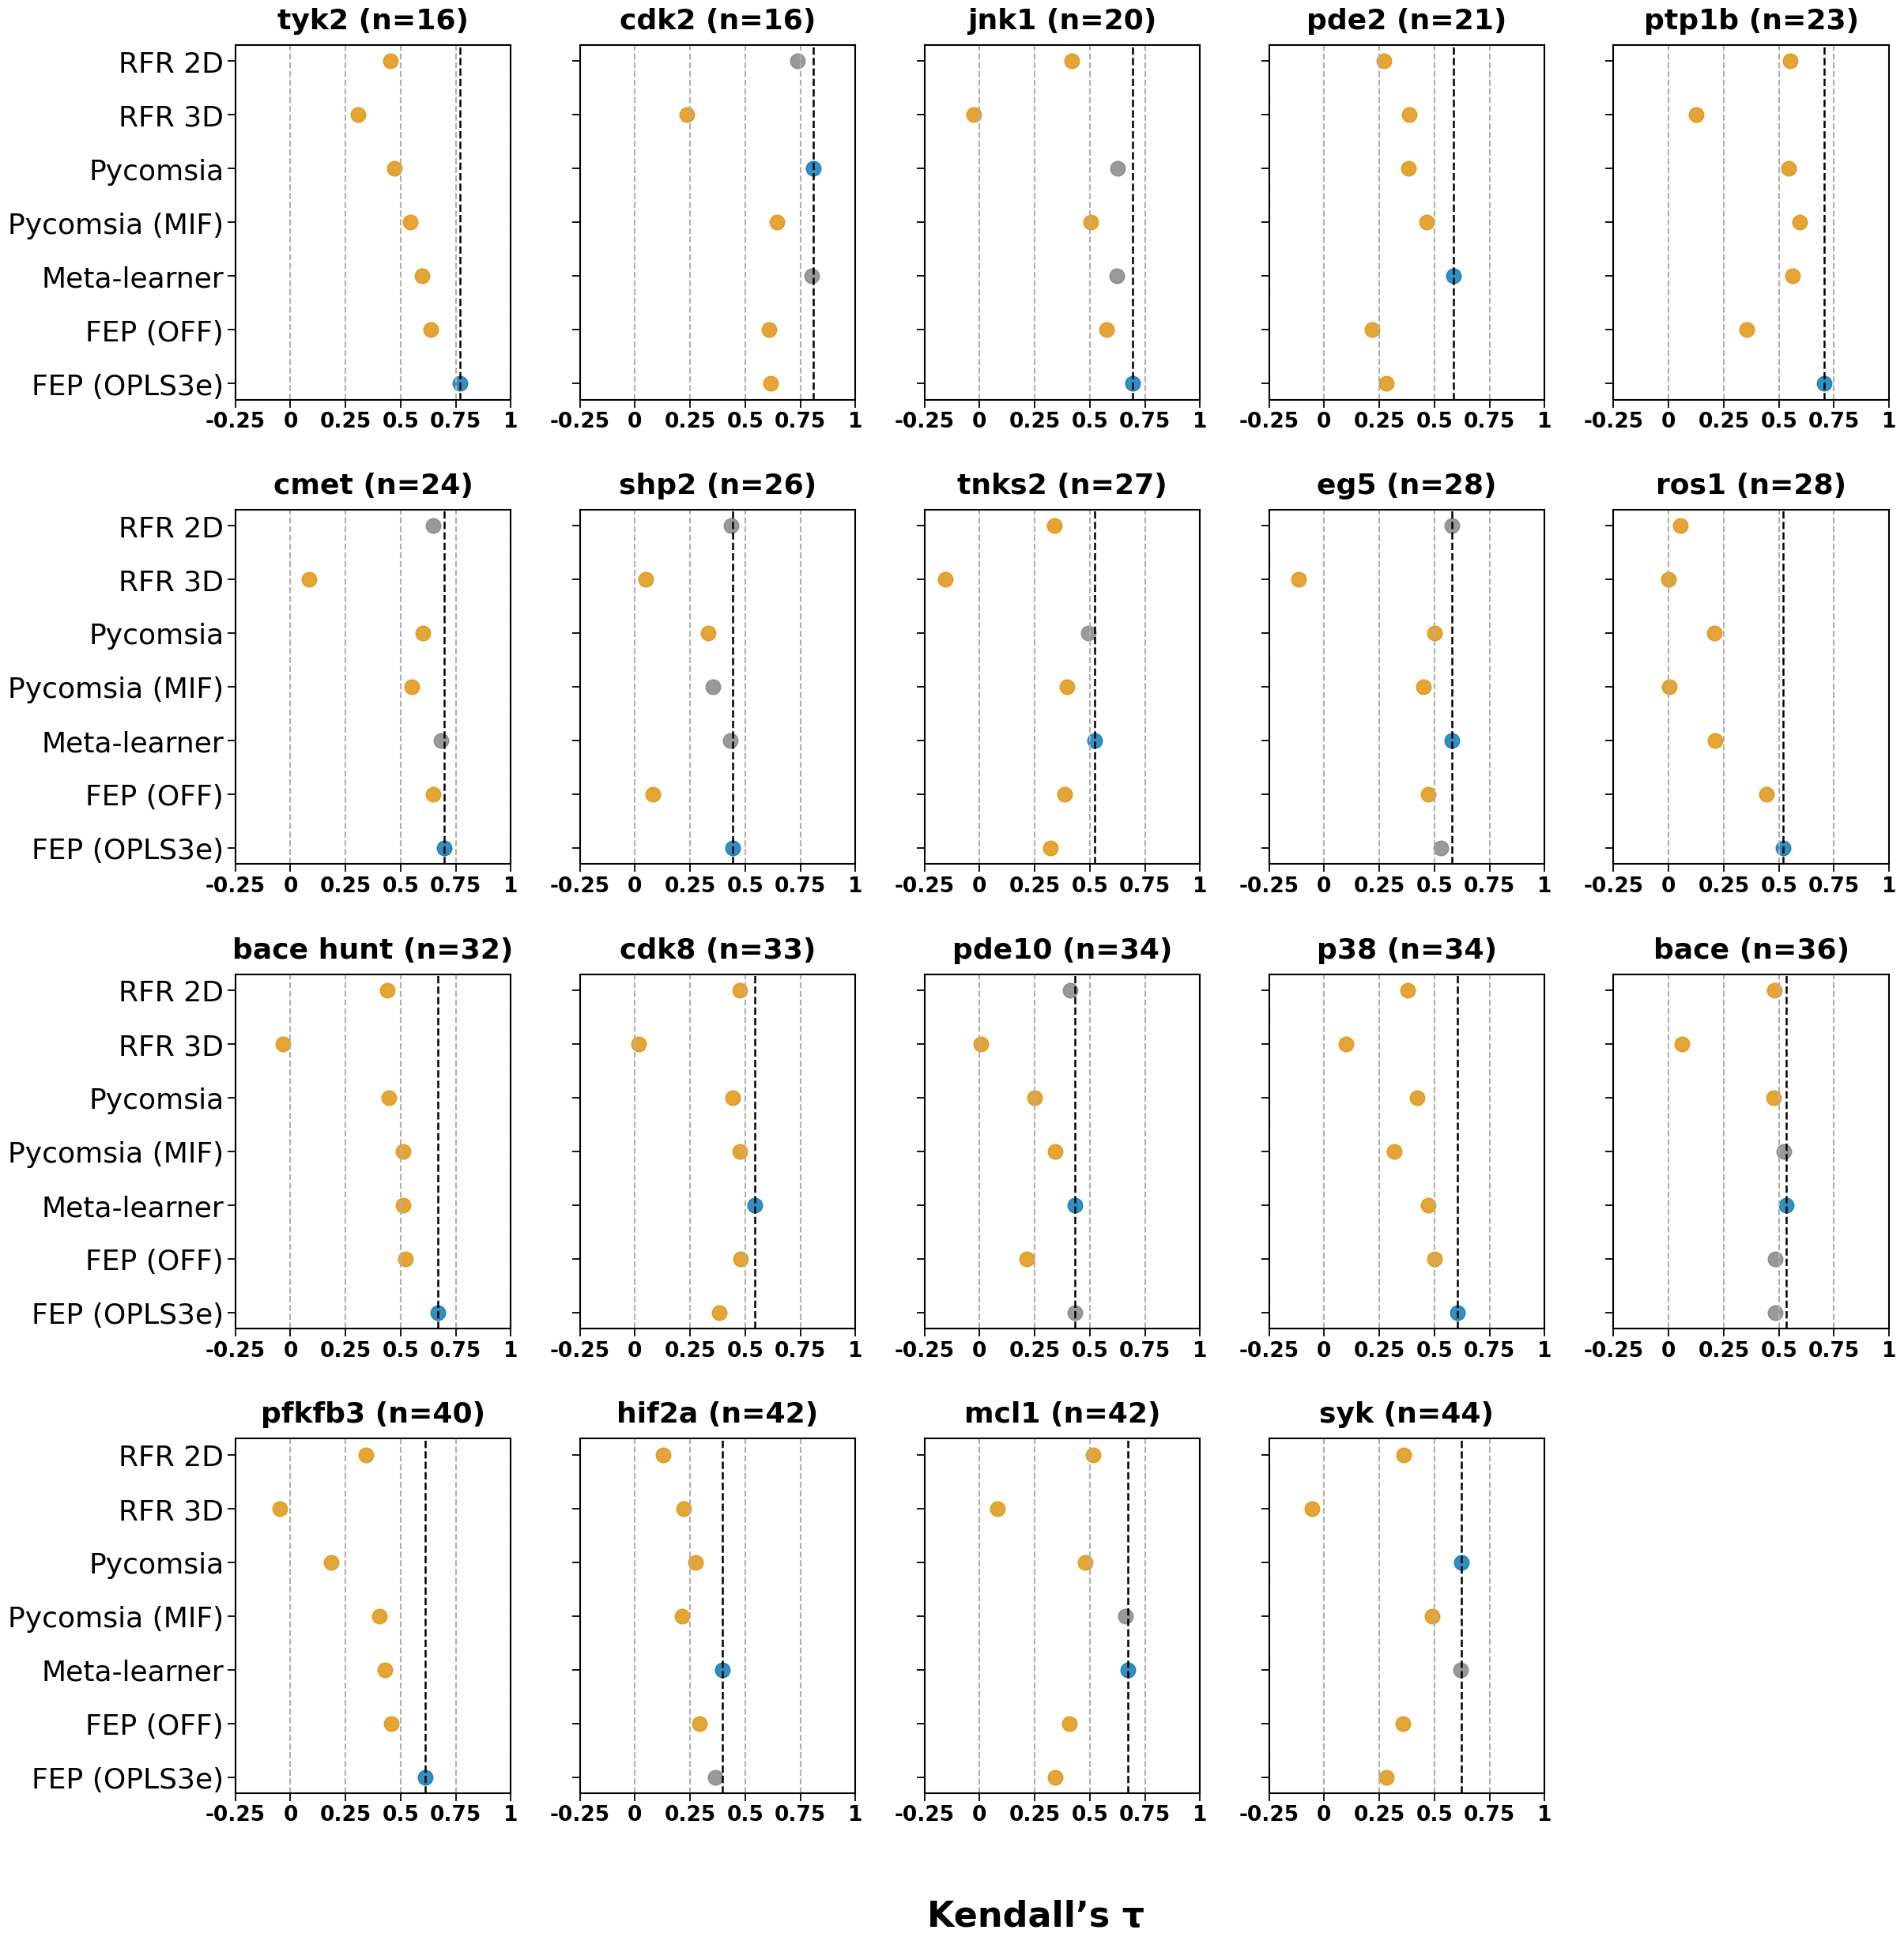

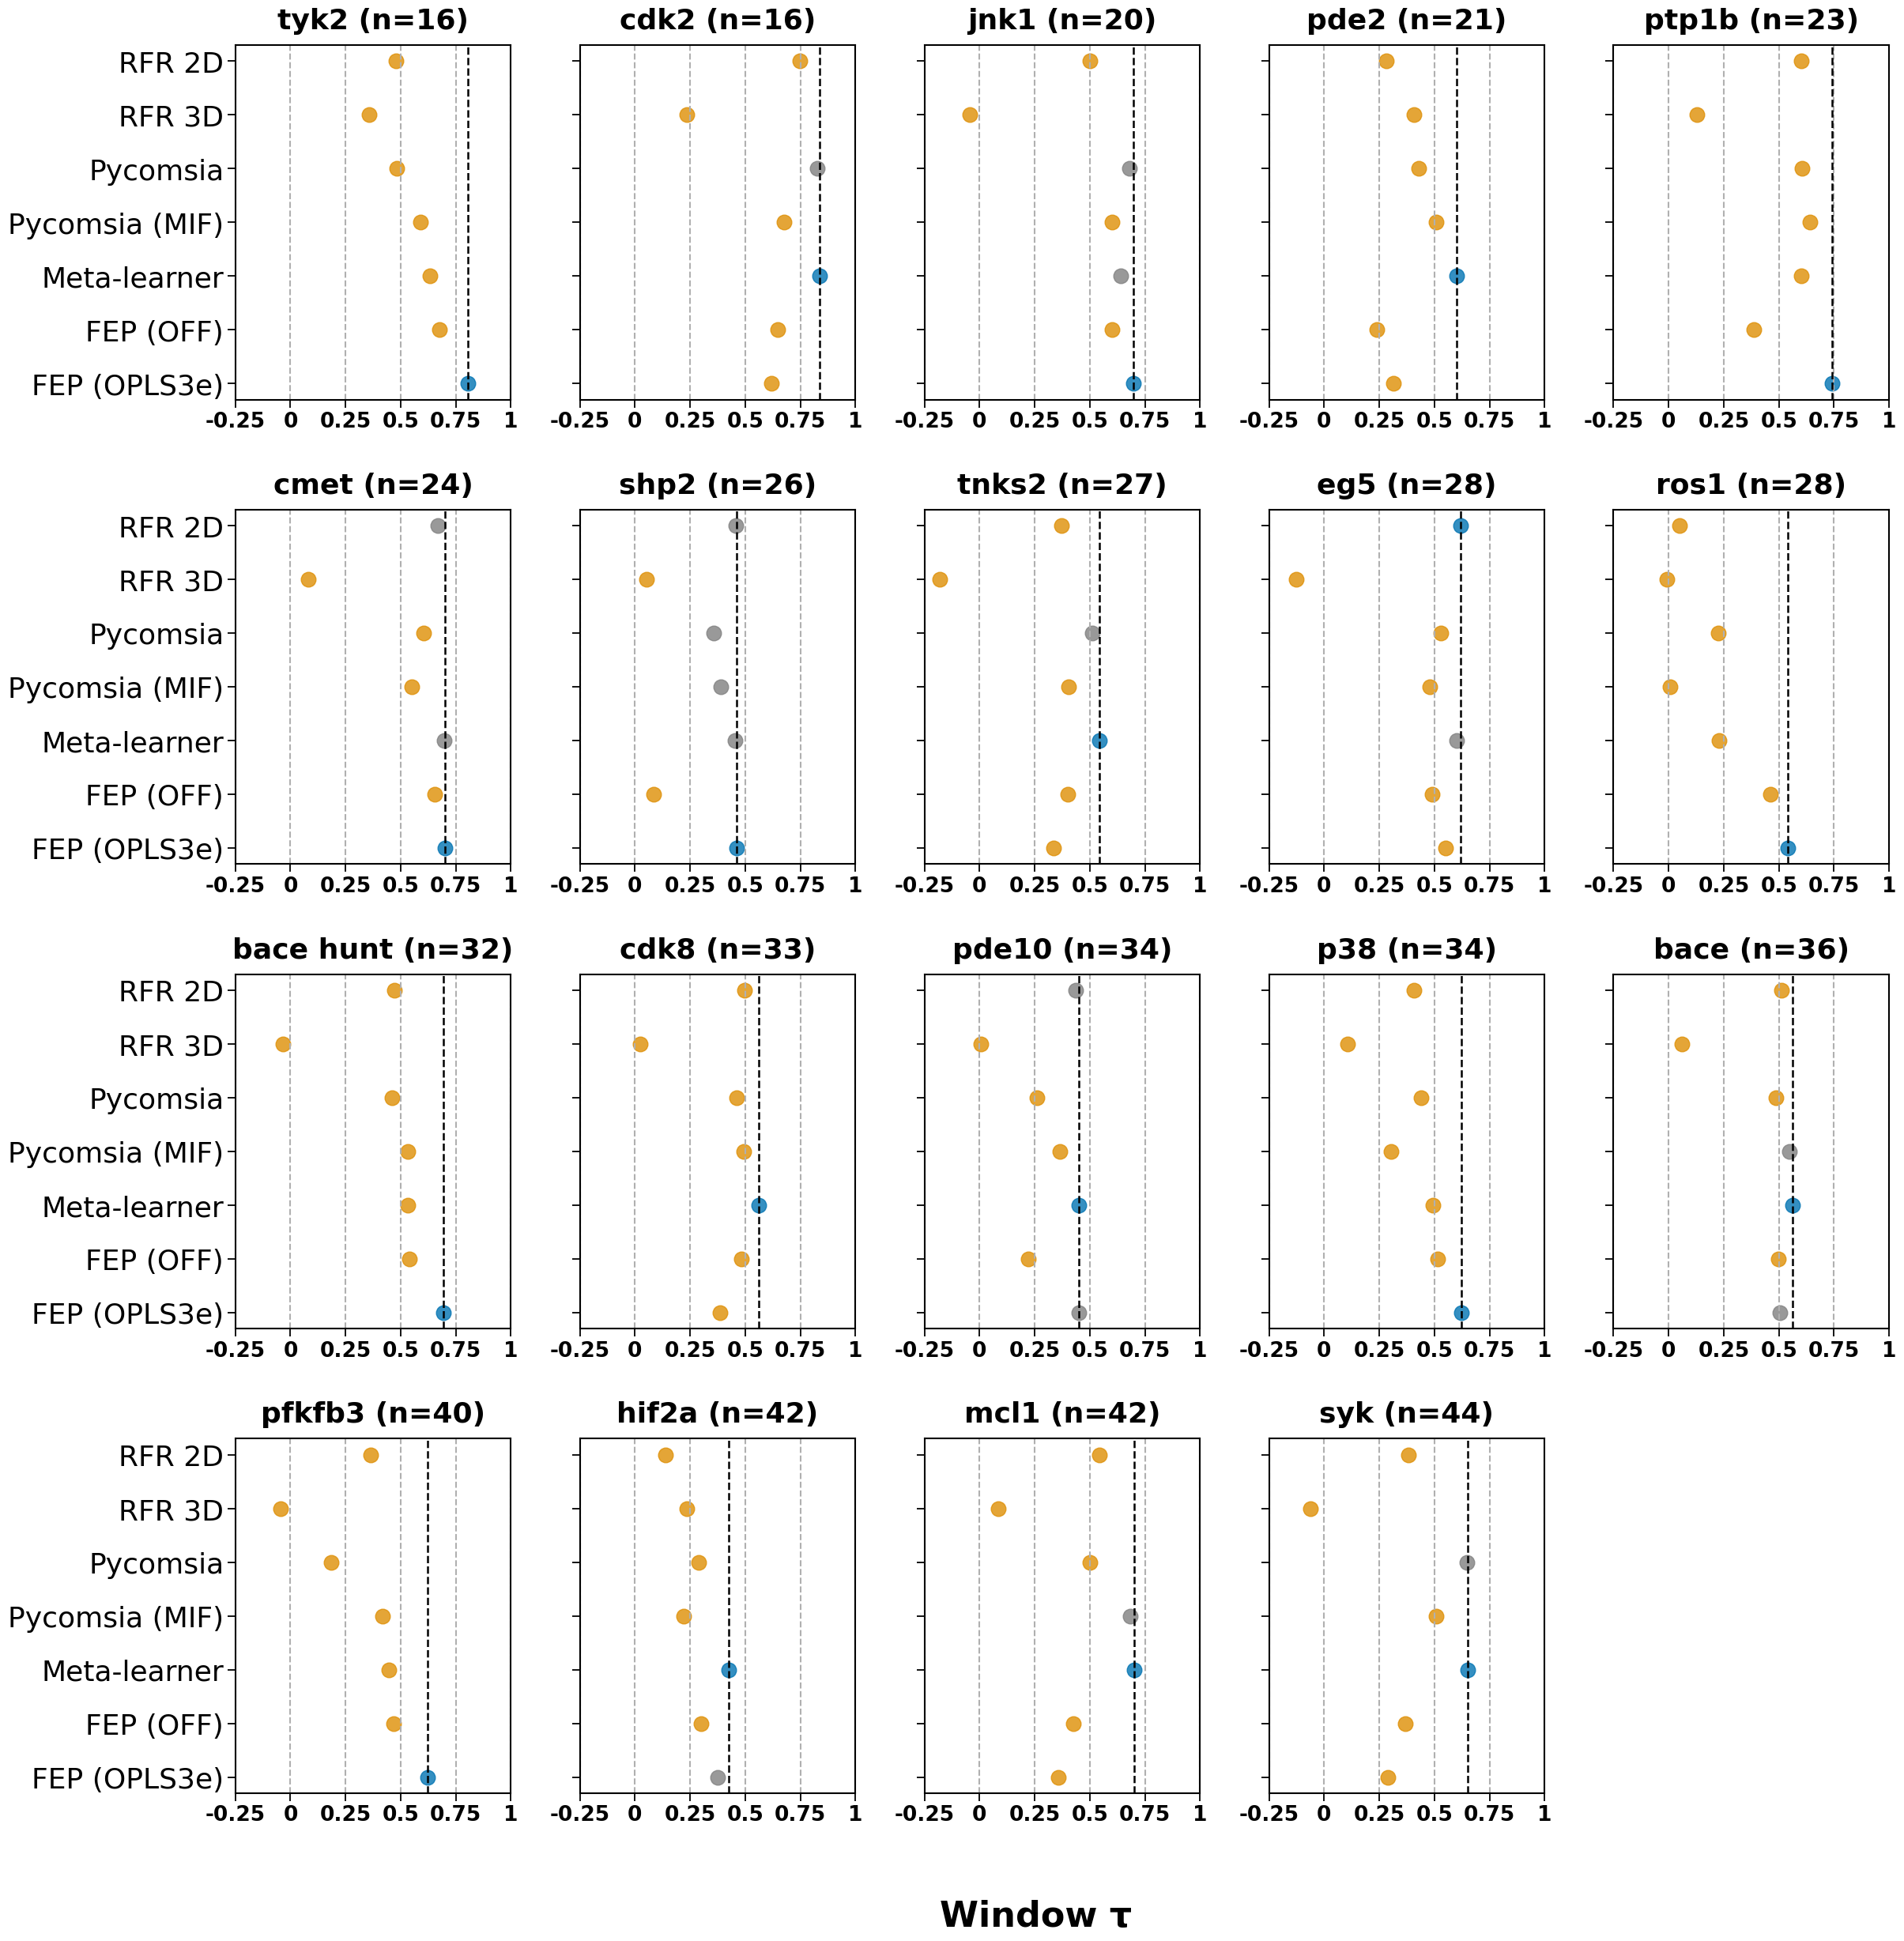

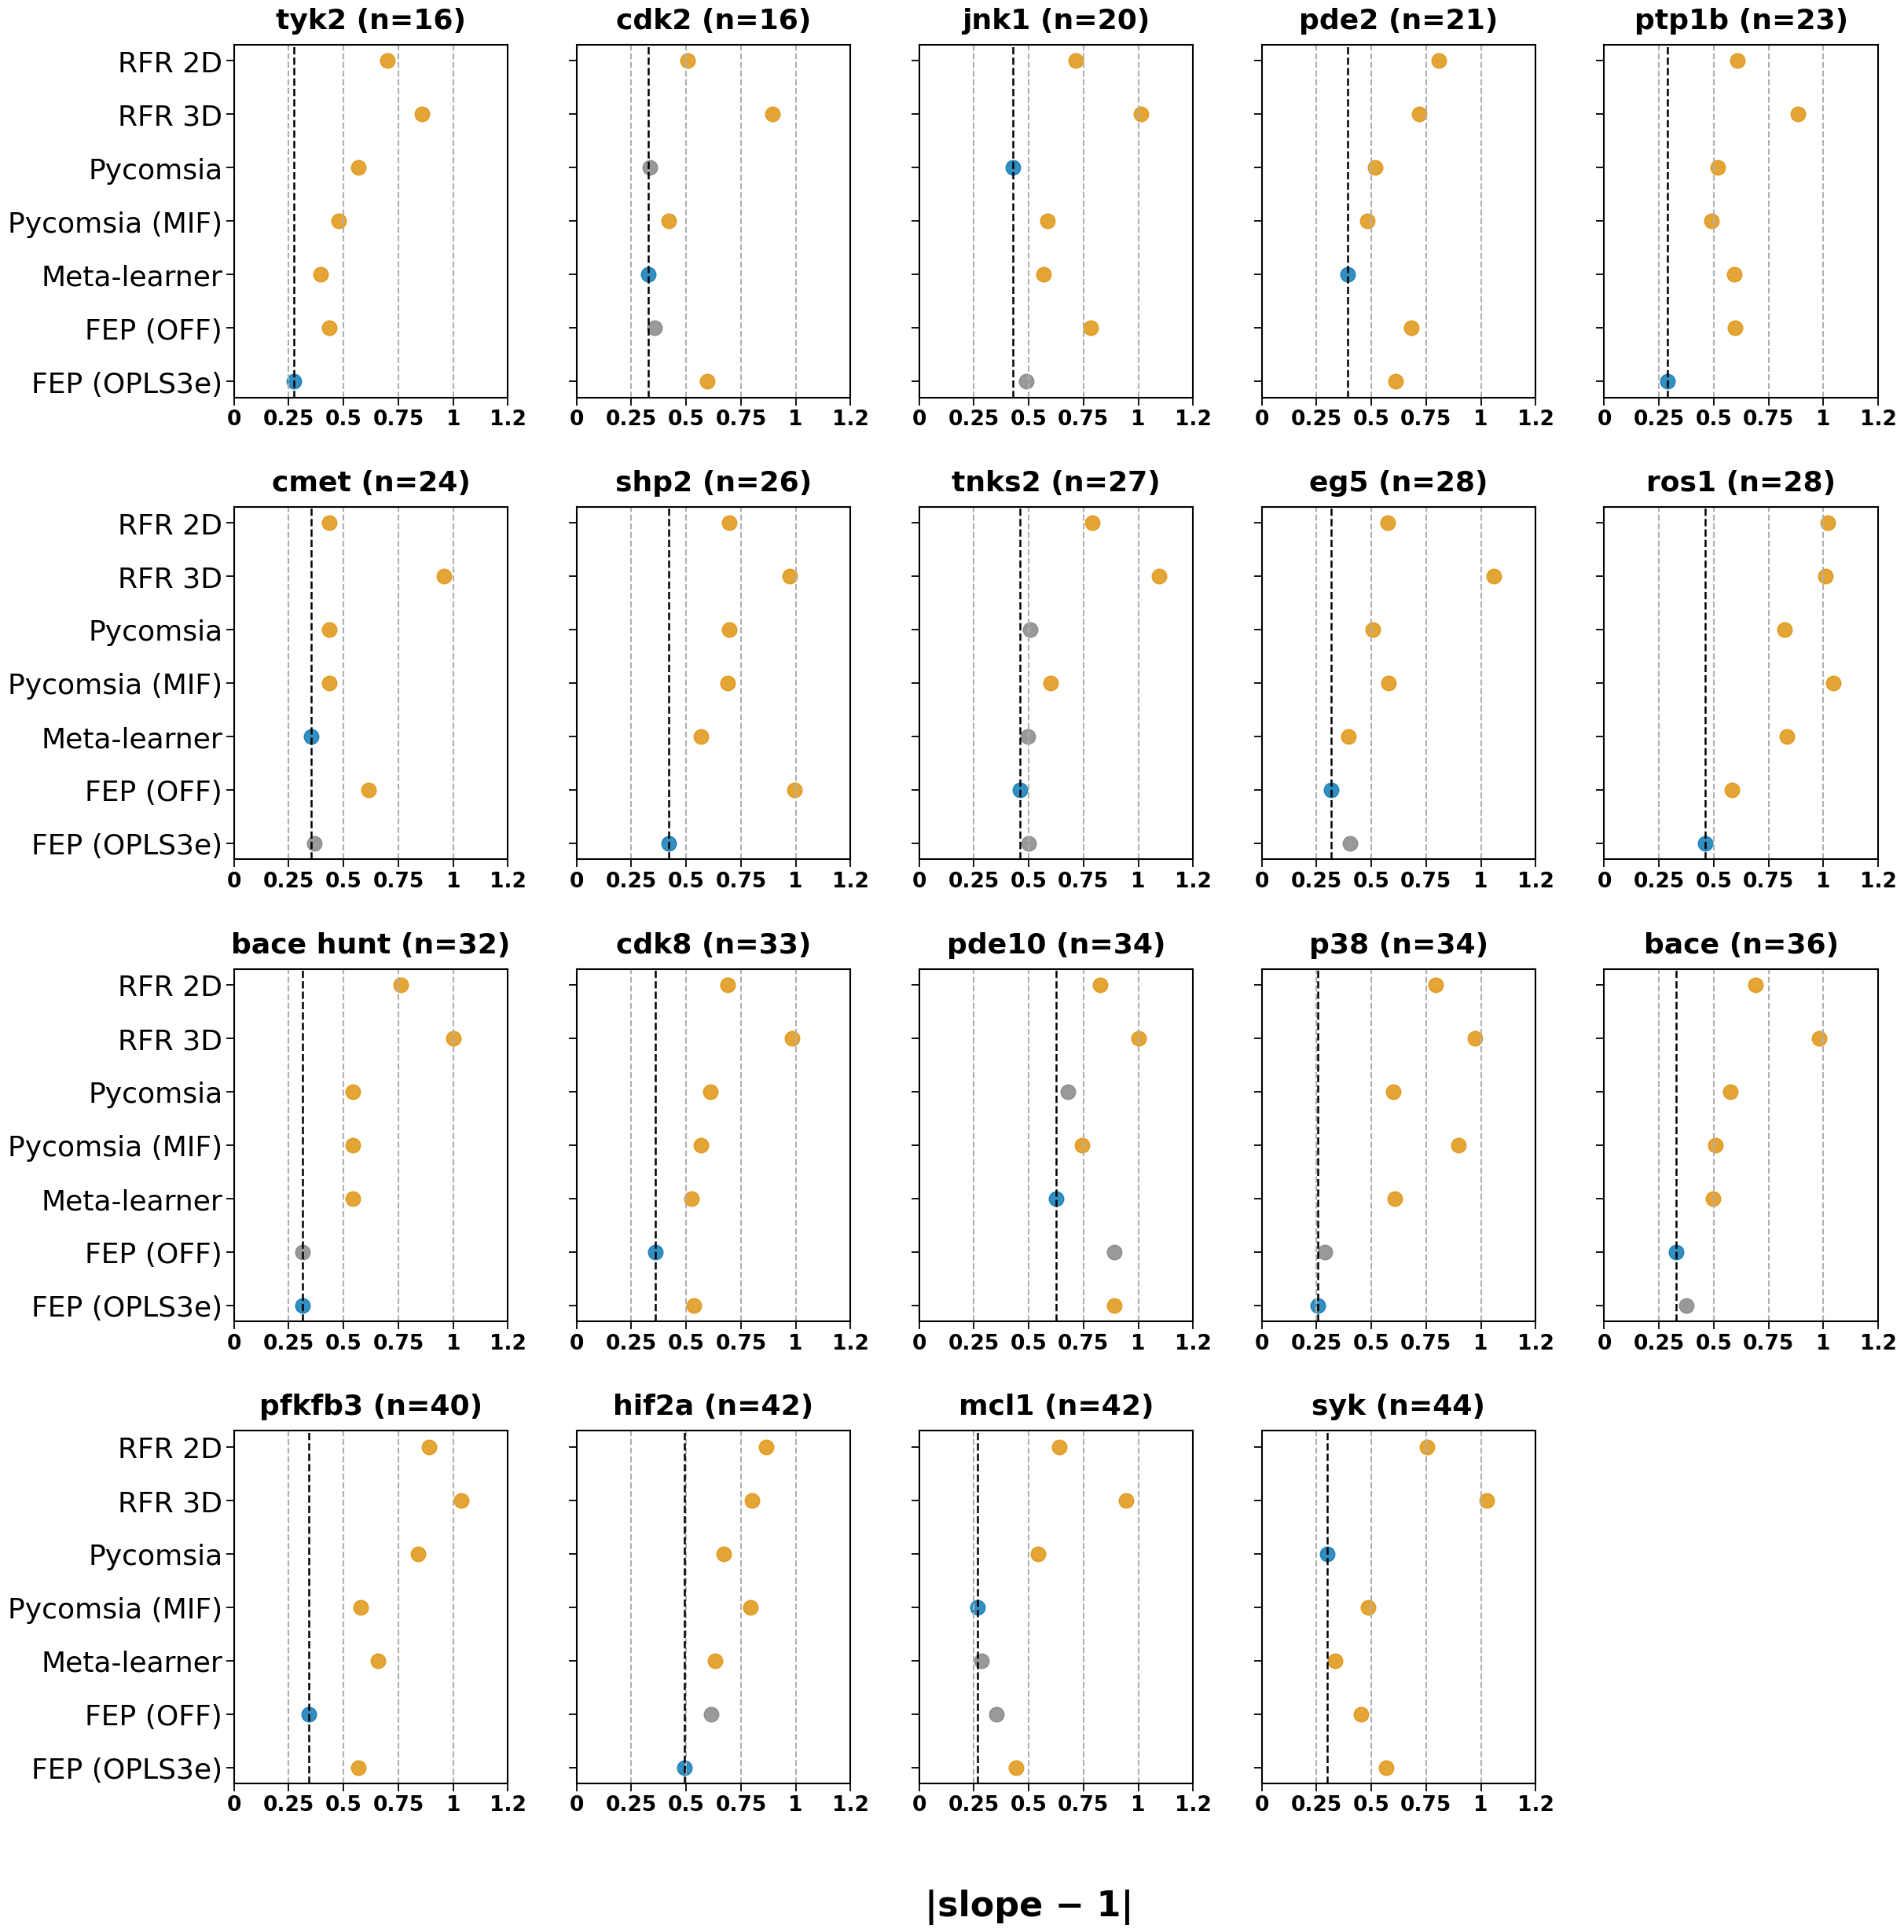

In [7]:
from DDG_ANALYSIS.E_EFFECT_SIZE_PLOT import plot_significance_ranks
plot_significance_ranks(results_all, DISPLAY_ORDER, ALPHA=ALPHA, METRICS=METRICS, target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json", prefix="RAND_")